# How many worlds? PCA and clustering of UN country data

**Research question:** Can countries be meaningfully divided into “developed” and “developing”, or is the structure more complex?

This notebook follows the class workflow: pandas, median imputation, `StandardScaler`, PCA, K-Means and an elbow plot. Silhouette scores and sensitivity checks help us judge the result.

**Main conclusion:** Two clusters give the clearest statistical split in our main model. Four clusters provide a useful, less separated descriptive view. Neither result establishes that there are exactly two or four natural kinds of country.

**Google Colab:** Upload this `.ipynb`, then select **Runtime → Run all**. The first data cell downloads the assigned CSV if `UN.csv` is not already present. No Drive mount or manual path changes are required. All charts and tables are already saved in this notebook.

The data cover **207 countries and territories around 1998**, not present-day conditions. Each row receives equal weight. Add your group members' names before submission.

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

SEED = 42
N_INIT = 50
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 160})
RESULTS = Path('results')
FIGURES = Path('figures')
RESULTS.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
COLORS = ['#C55A3E', '#D4A238', '#248E91', '#4264AB']

def save_figure(name):
    plt.tight_layout()
    plt.savefig(FIGURES / name, bbox_inches='tight')
    plt.show()
    plt.close()

## 1. Load and explore the data

We use the exact CSV supplied in the assignment. `country` is an identifier and `region` is a category, so neither belongs in a numerical PCA or distance calculation. We retain both for interpretation.

The fields match the historical **UN98** dataset. Its documentation also says that some literacy values were already regression-imputed by the source. Therefore, even non-missing values are not necessarily direct measurements.

Sources: [assigned CSV](https://raw.githubusercontent.com/manoelgadi/PSDMA/refs/heads/main/datasets/UN.csv), [UN98 data dictionary](https://vincentarelbundock.github.io/Rdatasets/doc/carData/UN98.html).

In [2]:
URL = 'https://raw.githubusercontent.com/manoelgadi/PSDMA/refs/heads/main/datasets/UN.csv'
DATA = Path('UN.csv')
if not DATA.exists():
    from urllib.request import urlretrieve
    urlretrieve(URL, DATA)
df = pd.read_csv(DATA)
print('Rows and columns:', df.shape)
print('Duplicate country names:', df['country'].duplicated().sum())
print('Duplicate rows:', df.duplicated().sum())
print('CSV SHA-256:', hashlib.sha256(DATA.read_bytes()).hexdigest())
display(df.head())
display(df.describe().T.round(2))

Rows and columns: (207, 14)
Duplicate country names: 0
Duplicate rows: 0
CSV SHA-256: f315e7b6c37c2bcbdfcc696a944d431f2f06e3d3cb51b21f5a3c9e646e23faf6


,country,region,tfr,contraception,educationMale,educationFemale,lifeMale,lifeFemale,infantMortality,GDPperCapita,economicActivityMale,economicActivityFemale,illiteracyMale,illiteracyFemale
0,Afghanistan,Asia,6.90,NaN,NaN,NaN,45.0,46.0,154.0,2848.0,87.5,7.2,52.800,85.00
1,Albania,Europe,2.60,NaN,NaN,NaN,68.0,74.0,32.0,863.0,NaN,NaN,NaN,NaN
2,Algeria,Africa,3.81,52.0,11.1,9.9,67.5,70.3,44.0,1531.0,76.4,7.8,26.100,51.00
3,American.Samoa,Asia,NaN,NaN,NaN,NaN,68.0,73.0,11.0,NaN,58.8,42.4,0.264,0.36
4,Andorra,Europe,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,count,mean,std,min,25%,50%,75%,max
tfr,197.0,3.53,1.76,1.19,1.95,3.07,4.98,8.0
contraception,144.0,43.43,23.71,2.00,21.00,47.00,64.00,86.0
educationMale,76.0,11.41,3.05,3.30,9.75,11.25,13.90,17.2
educationFemale,76.0,11.28,3.48,2.00,9.32,11.65,13.65,17.8
lifeMale,196.0,63.63,9.79,36.00,57.38,66.50,70.90,77.4
lifeFemale,196.0,68.39,11.04,39.10,59.60,72.15,76.43,82.9
infantMortality,201.0,43.48,38.76,2.00,12.00,30.00,66.00,169.0
GDPperCapita,197.0,6261.95,9355.66,36.00,442.00,1779.00,7272.00,42416.0
economicActivityMale,165.0,76.46,7.69,51.20,72.30,76.80,81.20,93.0
economicActivityFemale,165.0,46.79,16.81,1.90,37.00,48.40,56.40,90.6


,meaning,missing_n,missing_pct,included
tfr,"Total fertility, children per woman",10,4.83,True
contraception,"Married women using contraception, %",63,30.43,True
educationMale,Average years of male education,131,63.29,False
educationFemale,Average years of female education,131,63.29,False
lifeMale,"Male life expectancy at birth, years",11,5.31,True
lifeFemale,"Female life expectancy at birth, years",11,5.31,True
infantMortality,"Infant deaths per 1,000 live births",6,2.90,True
GDPperCapita,"GDP per person, US dollars in the historical s...",10,4.83,True
economicActivityMale,"Economically active men, %",42,20.29,True
economicActivityFemale,"Economically active women, %",42,20.29,True


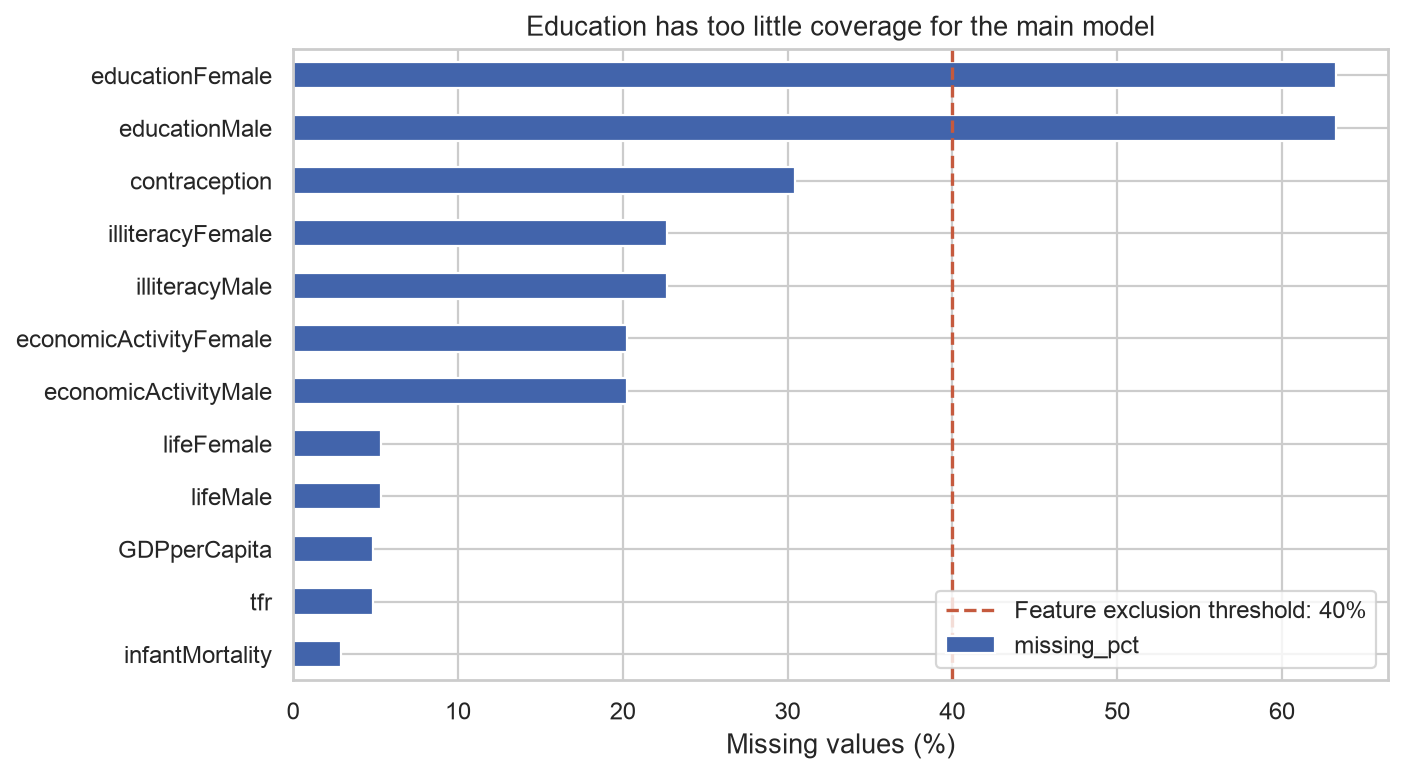

In [3]:
definitions = {
    'tfr': 'Total fertility, children per woman',
    'contraception': 'Married women using contraception, %',
    'educationMale': 'Average years of male education',
    'educationFemale': 'Average years of female education',
    'lifeMale': 'Male life expectancy at birth, years',
    'lifeFemale': 'Female life expectancy at birth, years',
    'infantMortality': 'Infant deaths per 1,000 live births',
    'GDPperCapita': 'GDP per person, US dollars in the historical source',
    'economicActivityMale': 'Economically active men, %',
    'economicActivityFemale': 'Economically active women, %',
    'illiteracyMale': 'Illiterate men aged 15+, %',
    'illiteracyFemale': 'Illiterate women aged 15+, %'
}
missing = pd.DataFrame({
    'meaning': pd.Series(definitions),
    'missing_n': df[list(definitions)].isna().sum(),
    'missing_pct': 100 * df[list(definitions)].isna().mean()
})
missing['included'] = missing['missing_pct'] <= 40
display(missing.round(2))
missing.to_csv(RESULTS / 'missing_values.csv')
missing['missing_pct'].sort_values().plot.barh(figsize=(9, 5), color='#4264AB')
plt.axvline(40, color='#C55A3E', linestyle='--', label='Feature exclusion threshold: 40%')
plt.xlabel('Missing values (%)')
plt.title('Education has too little coverage for the main model')
plt.legend(loc='lower right')
save_figure('01_missing_values.png')

### Missing-value decisions

1. Exclude numerical variables with over **40% missing values**. This removes both education variables (131 of 207 values missing each). The threshold is a transparent practical choice, not an optimized statistical cutoff.
2. Exclude rows missing **more than half of the remaining ten indicators**. Assigning these rows to clusters would largely describe imputed values. Keep an exclusion table rather than silently dropping them.
3. Fill the remaining gaps with each variable's **median among retained rows**, as in class. Medians resist extreme values better than means. Never replace missing socioeconomic measurements with zero.

Median imputation can pull countries toward the center and weaken correlations. We retain imputation counts for every country and compare the results with a complete-case analysis later. Missingness is unlikely to be random.

In [4]:
features = missing.index[missing['included']].tolist()
keep = df[features].isna().mean(axis=1) <= 0.5
excluded = df.loc[~keep, ['country', 'region']].copy()
excluded['missing_indicators'] = df.loc[~keep, features].isna().sum(axis=1)
raw = df.loc[keep].reset_index(drop=True)
imputed_count = raw[features].isna().sum(axis=1)
medians = raw[features].median()
X = raw[features].fillna(medians)
print(f'Retained {len(raw)} of {len(df)} rows and {len(features)} numerical indicators.')
print(f'Imputed {int(imputed_count.sum())} of {X.size} retained cells ({100*imputed_count.sum()/X.size:.1f}%).')
display(excluded)
display(pd.DataFrame({'imputation_median': medians}))
excluded.to_csv(RESULTS / 'excluded_countries.csv', index=False)

Retained 198 of 207 rows and 10 numerical indicators.
Imputed 224 of 1980 retained cells (11.3%).


,country,region,missing_indicators
4,Andorra,Europe,10
49,Dominica,America,6
51,East.Timor,Asia,6
66,Gaza.Strip,Asia,6
107,Liechtenstein,Europe,6
125,Monaco,Europe,9
190,Tuvalu,Oceania,10
201,Virgin.Islands,America,6
202,Western.Sahara,Africa,6


,imputation_median
tfr,3.055
contraception,47.000
lifeMale,66.650
lifeFemale,72.300
infantMortality,29.000
GDPperCapita,1712.000
economicActivityMale,76.800
economicActivityFemale,48.400
illiteracyMale,10.829
illiteracyFemale,20.100


### Outliers and scaling

We flag outliers using the **1.5 × IQR rule** on observed values before imputation. Flags identify values to inspect, not automatic errors. Very high GDP and extreme health outcomes are substantively relevant to this research question. We retain them because the file provides no evidence that they are recording errors. We do not delete wealthy or poor countries merely for being unusual.

The main model keeps the original numerical scales before standardization, matching class. A sensitivity analysis uses `log1p(GDPperCapita)` to reduce the influence of high GDP values without deleting countries.

`StandardScaler` gives each variable mean zero and population standard deviation one. Without scaling, dollar values could dominate years and percentages in PCA and Euclidean distances. **Scaling does not make a variable normally distributed**, and PCA does not require normally distributed inputs to compute its descriptive components.

,lower_fence,upper_fence,flagged_observations
tfr,-2.64,9.57,0
contraception,-43.50,128.50,0
lifeMale,37.09,91.19,1
lifeFemale,34.25,101.85,0
infantMortality,-69.00,147.00,4
GDPperCapita,-9590.00,17148.00,26
economicActivityMale,58.63,94.82,1
economicActivityFemale,7.73,85.52,5
illiteracyMale,-33.98,64.51,2
illiteracyFemale,-59.92,112.79,0


,country,GDPperCapita
173,Switzerland,42416.0
88,Japan,41718.0
104,Luxembourg,35109.0
134,Norway,33734.0
46,Denmark,33191.0
64,Germany,29632.0
9,Austria,29006.0
16,Belgium,26582.0
58,France,26444.0
172,Sweden,26253.0


,scaled_mean,scaled_sd
tfr,-0.0,1.0
contraception,0.0,1.0
lifeMale,0.0,1.0
lifeFemale,0.0,1.0
infantMortality,-0.0,1.0
GDPperCapita,0.0,1.0
economicActivityMale,-0.0,1.0
economicActivityFemale,0.0,1.0
illiteracyMale,-0.0,1.0
illiteracyFemale,-0.0,1.0


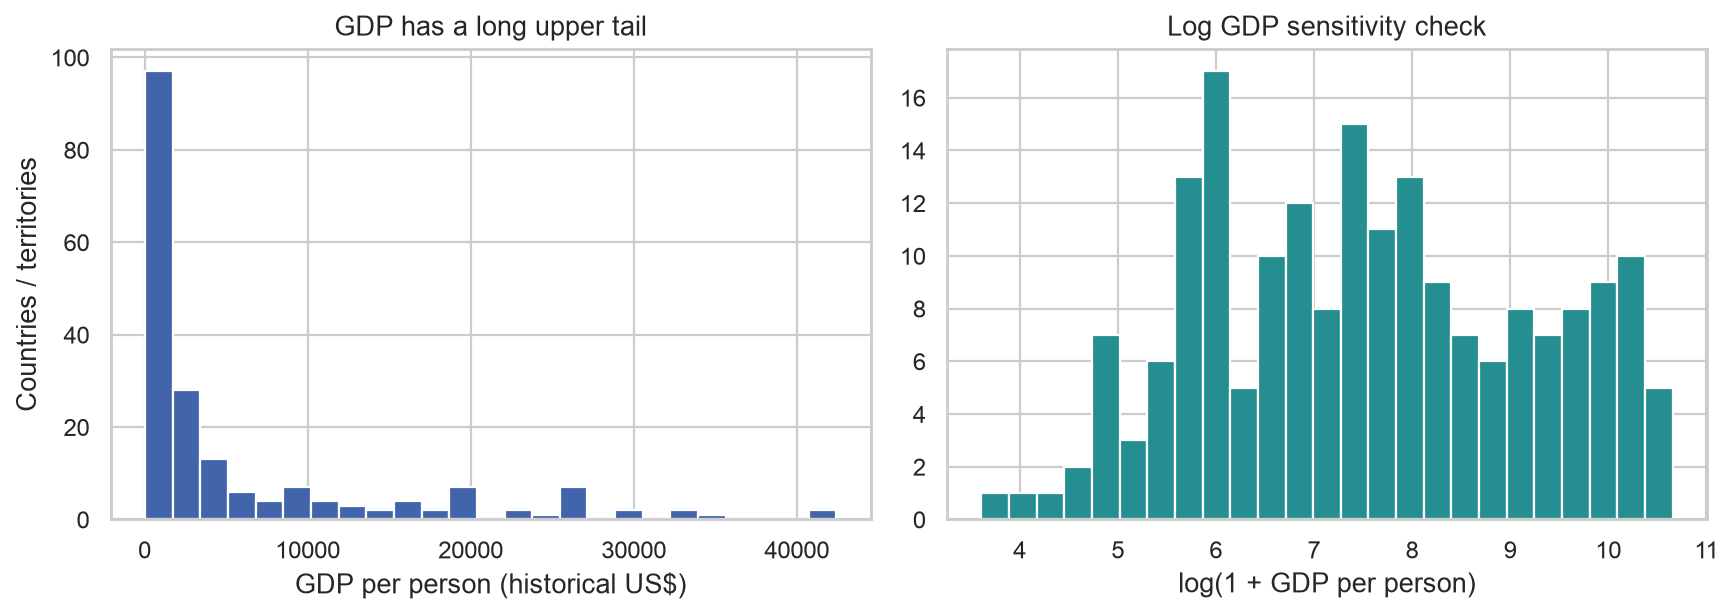

In [5]:
q1 = raw[features].quantile(.25)
q3 = raw[features].quantile(.75)
iqr = q3 - q1
flags = raw[features].lt(q1 - 1.5*iqr) | raw[features].gt(q3 + 1.5*iqr)
outlier_table = pd.DataFrame({
    'lower_fence': q1 - 1.5*iqr,
    'upper_fence': q3 + 1.5*iqr,
    'flagged_observations': flags.sum()
})
display(outlier_table.round(2))
display(raw.loc[flags['GDPperCapita'], ['country', 'GDPperCapita']].sort_values('GDPperCapita', ascending=False))
outlier_table.to_csv(RESULTS / 'outlier_summary.csv')
flagged_rows = flags.stack()
flagged_rows = flagged_rows[flagged_rows].reset_index().rename(columns={'level_0':'row', 'level_1':'variable'})
flagged_rows['country'] = flagged_rows['row'].map(raw['country'])
flagged_rows['value'] = [raw.loc[r, v] for r, v in zip(flagged_rows['row'], flagged_rows['variable'])]
flagged_rows[['country', 'variable', 'value']].to_csv(RESULTS / 'outlier_flags.csv', index=False)

scaler = StandardScaler()
Z = scaler.fit_transform(X)
assert np.isfinite(Z).all()
assert np.allclose(Z.mean(axis=0), 0, atol=1e-10)
assert np.allclose(Z.std(axis=0), 1)
display(pd.DataFrame({'scaled_mean': Z.mean(axis=0), 'scaled_sd': Z.std(axis=0)}, index=features).round(6))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(raw['GDPperCapita'].dropna(), bins=25, color='#4264AB')
axes[0].set(xlabel='GDP per person (historical US$)', ylabel='Countries / territories', title='GDP has a long upper tail')
axes[1].hist(np.log1p(raw['GDPperCapita'].dropna()), bins=25, color='#248E91')
axes[1].set(xlabel='log(1 + GDP per person)', title='Log GDP sensitivity check')
save_figure('02_gdp_outliers.png')

## 2. PCA: main dimensions of country differences

Fit the full PCA to inspect every component. Then retain the smallest number explaining at least **90%** of the standardized variance. Cluster using **all retained components**, not just the two displayed on a scatter plot.

We do not whiten the components. Whitening would give a low-variance component as much weight as a high-variance one and change the distance definition.

5 components retain 93.22% of variance.
The two-dimensional plot displays 69.62% of variance.


,component,explained_pct,cumulative_pct
0,PC1,58.39,58.39
1,PC2,11.23,69.62
2,PC3,10.81,80.43
3,PC4,7.83,88.26
4,PC5,4.96,93.22
5,PC6,3.98,97.20
6,PC7,1.63,98.83
7,PC8,0.70,99.53
8,PC9,0.36,99.90
9,PC10,0.10,100.00


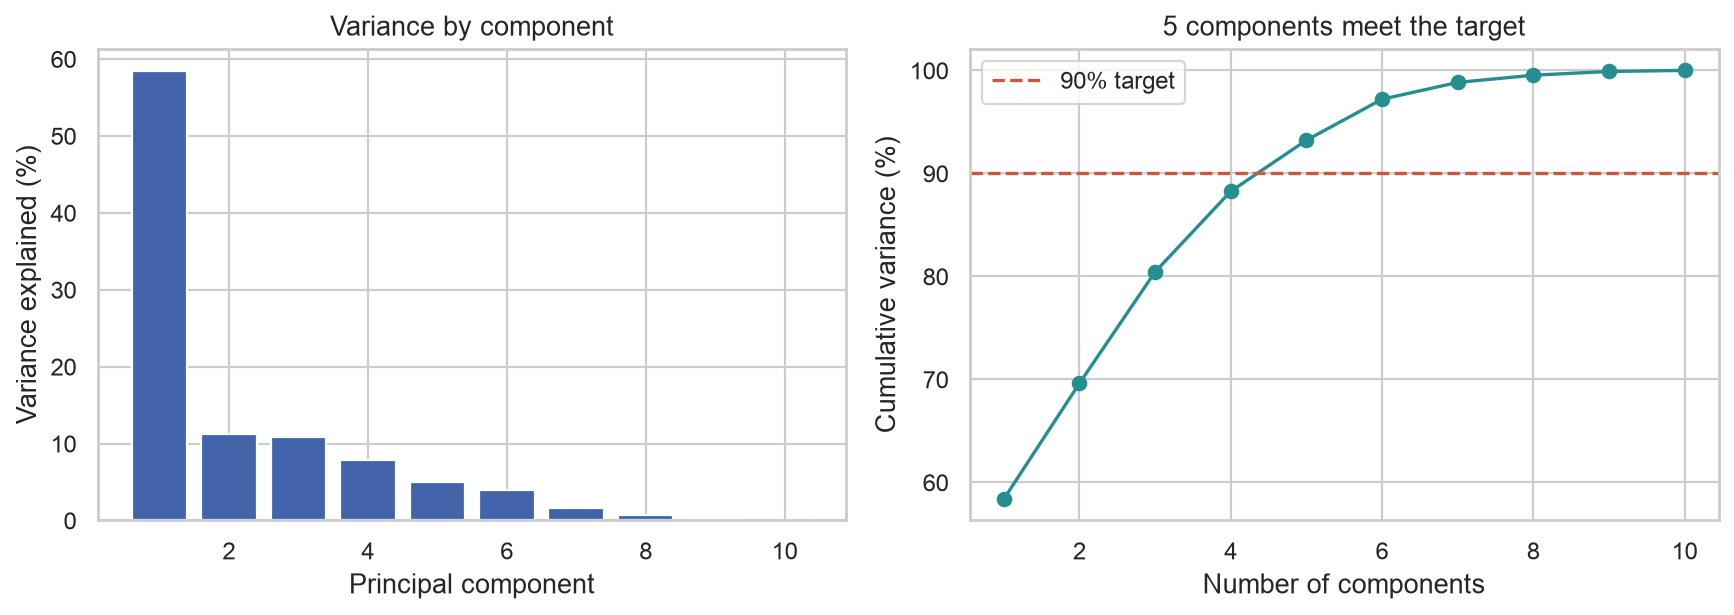

In [6]:
pca = PCA(svd_solver='full')
scores = pca.fit_transform(Z)
evr = pca.explained_variance_ratio_
cumulative = np.cumsum(evr)
n90 = int(np.searchsorted(cumulative, 0.90) + 1)
PC = scores[:, :n90]
variance = pd.DataFrame({
    'component': [f'PC{i+1}' for i in range(len(features))],
    'explained_pct': 100*evr,
    'cumulative_pct': 100*cumulative
})
display(variance.round(2))
print(f'{n90} components retain {100*cumulative[n90-1]:.2f}% of variance.')
print(f'The two-dimensional plot displays {100*cumulative[1]:.2f}% of variance.')
variance.to_csv(RESULTS / 'pca_variance.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(range(1, len(features)+1), 100*evr, color='#4264AB')
axes[0].set(xlabel='Principal component', ylabel='Variance explained (%)', title='Variance by component')
axes[1].plot(range(1, len(features)+1), 100*cumulative, marker='o', color='#248E91')
axes[1].axhline(90, linestyle='--', color='#C55A3E', label='90% target')
axes[1].set(xlabel='Number of components', ylabel='Cumulative variance (%)', title=f'{n90} components meet the target')
axes[1].legend()
save_figure('03_pca_variance.png')

### Which variables matter?

The table reports **component coefficients** (eigenvector weights), often called loadings in class. Their squared values sum to one within each component. A larger absolute coefficient means a variable contributes more to that component. The contribution table reports **100 × squared coefficient**.

A component's overall sign is arbitrary. Interpret variables with the same or opposite signs together, rather than treating “positive” as inherently good. Correlated health measures can receive repeated weight in the analysis despite standardization.

component,PC1,PC2,PC3,PC4,PC5
tfr,-0.372,-0.080,0.012,0.092,-0.103
contraception,0.300,0.188,0.172,0.009,0.887
lifeMale,0.381,-0.081,0.250,0.137,-0.164
lifeFemale,0.394,-0.055,0.168,0.094,-0.163
infantMortality,-0.389,0.052,-0.089,-0.126,0.182
GDPperCapita,0.234,0.198,0.512,-0.497,-0.274
economicActivityMale,-0.169,0.439,0.384,0.749,-0.095
economicActivityFemale,0.023,0.845,-0.324,-0.235,-0.132
illiteracyMale,-0.338,0.015,0.433,-0.193,0.049
illiteracyFemale,-0.350,0.000,0.412,-0.219,0.112


component,PC1,PC2,PC3
tfr,13.8,0.6,0.0
contraception,9.0,3.5,3.0
lifeMale,14.5,0.7,6.3
lifeFemale,15.5,0.3,2.8
infantMortality,15.1,0.3,0.8
GDPperCapita,5.5,3.9,26.2
economicActivityMale,2.9,19.2,14.8
economicActivityFemale,0.1,71.4,10.5
illiteracyMale,11.4,0.0,18.7
illiteracyFemale,12.2,0.0,17.0


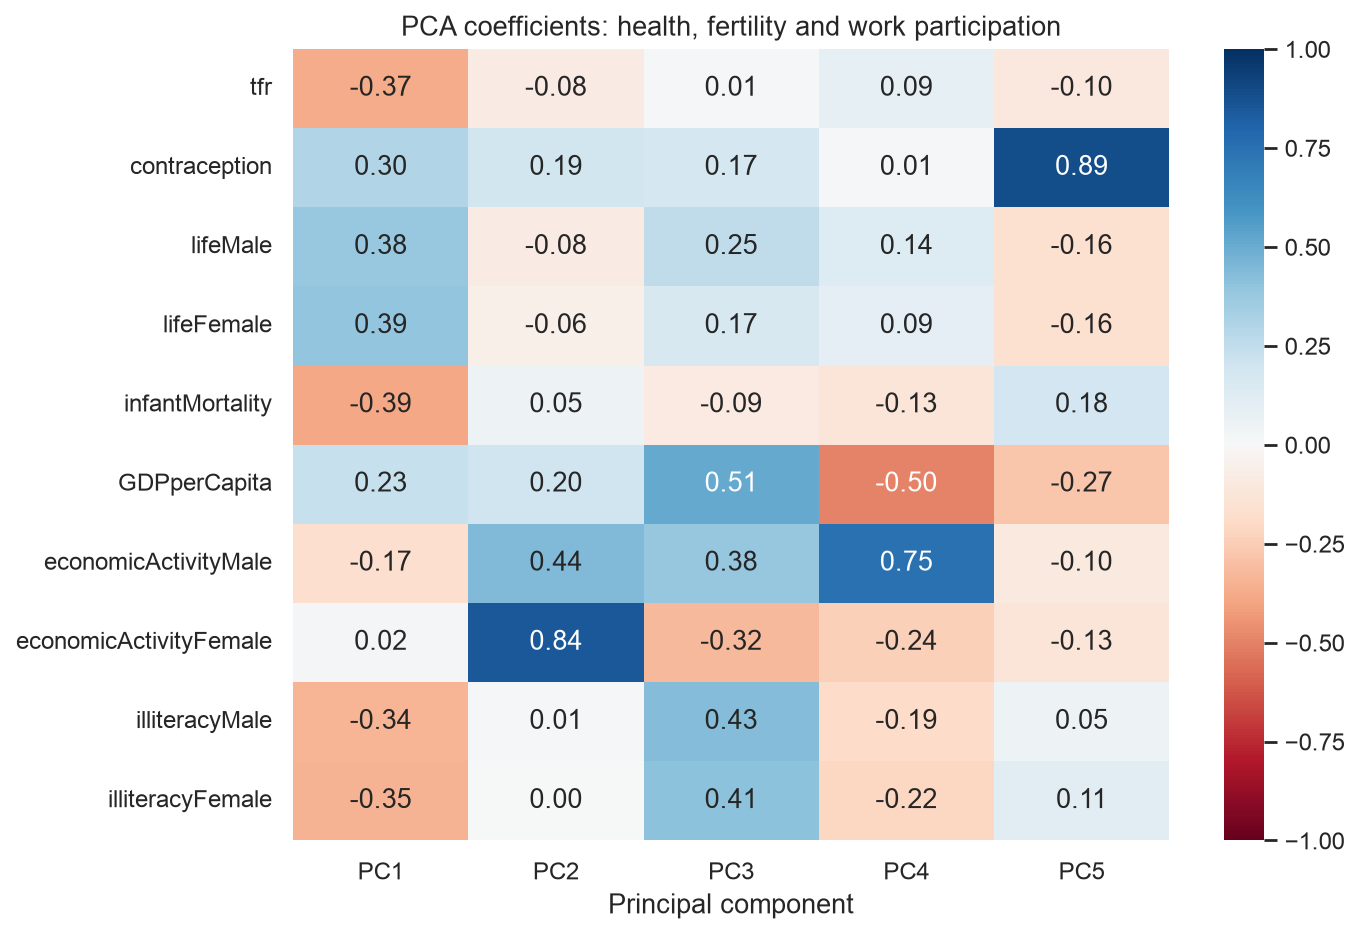

In [7]:
weights = pd.DataFrame(pca.components_.T, index=features, columns=variance['component'])
contributions = weights.pow(2) * 100
display(weights.iloc[:, :n90].round(3))
display(contributions.iloc[:, :3].round(1))
weights.to_csv(RESULTS / 'pca_coefficients.csv')
contributions.to_csv(RESULTS / 'pca_contributions_pct.csv')
plt.figure(figsize=(9, 6))
sns.heatmap(weights.iloc[:, :n90], annot=True, fmt='.2f', cmap='RdBu', center=0, vmin=-1, vmax=1)
plt.title('PCA coefficients: health, fertility and work participation')
plt.xlabel('Principal component')
plt.ylabel('')
save_figure('04_pca_coefficients.png')

**Interpretation:** PC1 contrasts longer life expectancy and greater contraception use with higher infant mortality, fertility and illiteracy. It summarizes a broad health and social development gradient. PC2 is dominated by female economic activity, with male economic activity also contributing. Participation can reflect different social arrangements and economic necessity, so it is not a simple prosperity ranking. PC3 combines GDP, illiteracy and economic activity, capturing differences not summarized by PC1.

PCA is useful here: five components retain about 93% of the variance from ten indicators and remove correlation among the component axes. It does not guarantee better clusters, remove all noise, or solve missing-data bias. Keeping all ten PCs would simply rotate the data and preserve every Euclidean distance.

## 3. K-Means: two clusters versus more detailed alternatives

We fit `k=1,...,8`, using `random_state=42` and **50 initializations** per fit. The elbow uses actual K-Means **inertia**, the sum of squared distances to the assigned centroid. This differs from averaging unsquared distances.

Silhouette ranges from −1 to 1 and compares a country's closeness to its own cluster with its nearest alternative cluster. Larger values indicate clearer separation. It is undefined for k=1. Inertia always improves when k increases, so a lower inertia alone cannot justify more clusters.

We report `1 − WCSS/TSS` as the fraction of **retained PCA-space dispersion** represented by cluster centers. This is a descriptive fit measure, not accuracy and not PCA's explained variance. We also calculate the same quantity against all ten standardized variables to show the effect of omitted PCs.

Preferred statistical model by silhouette: 2


,inertia,silhouette,dispersion_captured_pc_pct,dispersion_captured_full_pct,smallest_cluster,inertia_reduction_from_previous_pct
k,,,,,,
1,1845.755,NaN,-0.000,0.000,198,NaN
2,952.345,0.442,48.404,45.149,60,48.404
3,772.565,0.283,58.144,54.314,50,18.878
4,655.104,0.284,64.508,60.560,31,15.204
5,568.021,0.273,69.226,65.407,26,13.293
6,496.488,0.259,73.101,69.184,23,12.593
7,457.864,0.261,75.194,71.159,6,7.779
8,428.070,0.238,76.808,72.704,6,6.507


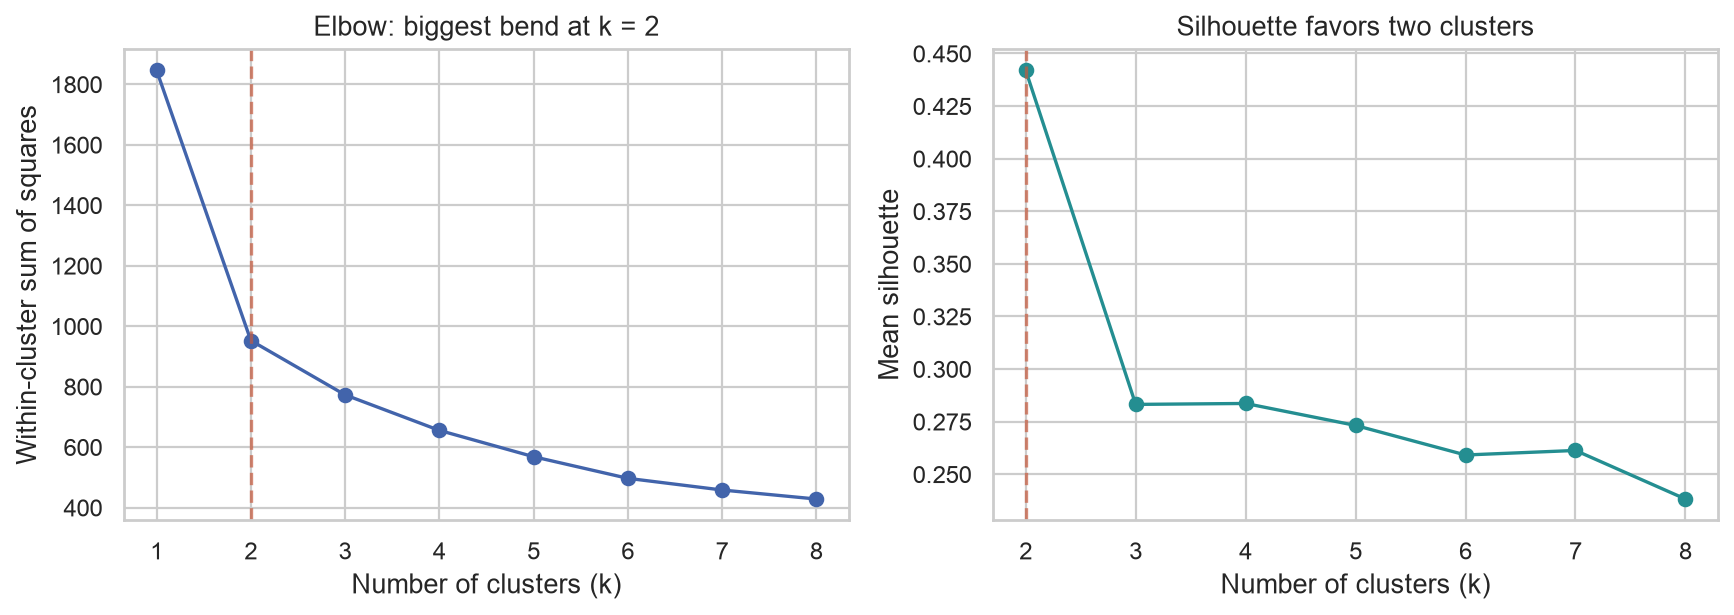

In [8]:
models = {}
rows = []
tss_pc = np.square(PC - PC.mean(axis=0)).sum()
tss_full = np.square(Z - Z.mean(axis=0)).sum()
for k in range(1, 9):
    km = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(PC)
    models[k] = km
    centers_full = np.vstack([Z[km.labels_ == j].mean(axis=0) for j in range(k)])
    within_full = np.square(Z - centers_full[km.labels_]).sum()
    rows.append({
        'k': k, 'inertia': km.inertia_,
        'silhouette': silhouette_score(PC, km.labels_) if k > 1 else np.nan,
        'dispersion_captured_pc_pct': 100*(1-km.inertia_/tss_pc),
        'dispersion_captured_full_pct': 100*(1-within_full/tss_full),
        'smallest_cluster': np.bincount(km.labels_).min()
    })
metrics = pd.DataFrame(rows).set_index('k')
metrics['inertia_reduction_from_previous_pct'] = -metrics['inertia'].pct_change()*100
display(metrics.round(3))
metrics.to_csv(RESULTS / 'cluster_metrics.csv')
best_k = int(metrics['silhouette'].idxmax())
print('Preferred statistical model by silhouette:', best_k)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(metrics.index, metrics['inertia'], marker='o', color='#4264AB')
axes[0].set(xlabel='Number of clusters (k)', ylabel='Within-cluster sum of squares', title='Elbow: biggest bend at k = 2', xticks=range(1, 9))
axes[1].plot(metrics.index[1:], metrics['silhouette'].iloc[1:], marker='o', color='#248E91')
axes[1].set(xlabel='Number of clusters (k)', ylabel='Mean silhouette', title='Silhouette favors two clusters', xticks=range(2, 9))
for ax in axes:
    ax.axvline(2, color='#C55A3E', linestyle='--', alpha=.7)
save_figure('05_cluster_selection.png')

### Selection decision

**Our preferred statistical solution is k=2**, supported by the largest elbow bend and the highest silhouette score. The richer **k=4** solution is a secondary descriptive comparison, not a claim that four clusters fit the separation evidence better. The k=3 and k=4 silhouettes are almost equal and substantially below k=2. There is no strong second elbow establishing exactly four groups.

This means the requested comparison between two clusters and the preferred number coincides at k=2. To make the comparison informative, we also examine k=4, quantify what it adds and give a representative country for every one of its groups.

Total variation in the five retained PCs (TSS): 1845.754967
k=2: 100 × (1 - 952.344658 / 1845.754967) = 48.4035%
k=4: 100 × (1 - 655.104447 / 1845.754967) = 64.5075%
This measures variation represented by cluster centers, not classification accuracy.


,inertia,silhouette,dispersion_captured_pc_pct,dispersion_captured_full_pct,smallest_cluster,inertia_reduction_from_previous_pct
k,,,,,,
2,952.345,0.442,48.404,45.149,60,48.404
4,655.104,0.284,64.508,60.560,31,15.204


Four-cluster group,1,2,3,4
Two-cluster group,,,,
1,51,9,0,0
2,0,23,84,31


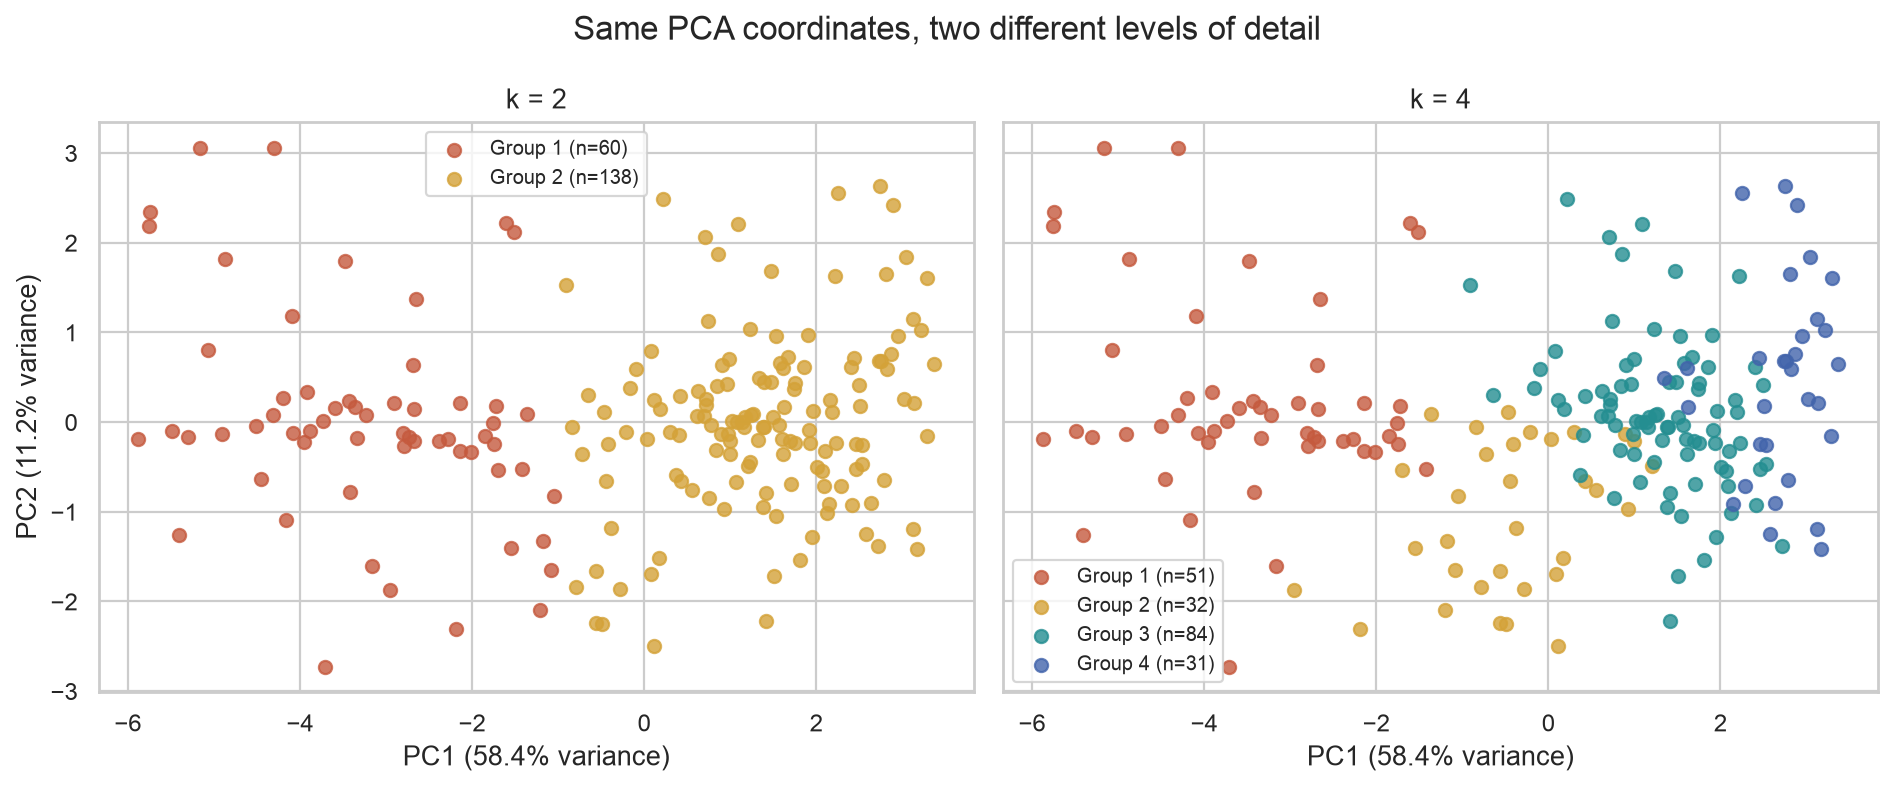

In [9]:
# Sort cluster labels by observed median GDP for readable, reproducible numbering.
# This naming step does not alter any assignments or imply official income levels.
def ordered_labels(model, data):
    order = data.assign(cluster=model.labels_).groupby('cluster')['GDPperCapita'].median().sort_values().index
    mapping = {old: new+1 for new, old in enumerate(order)}
    return np.array([mapping[x] for x in model.labels_])

labels2 = ordered_labels(models[2], raw)
labels4 = ordered_labels(models[4], raw)
comparison = metrics.loc[[2, 4]].copy()
display(comparison.round(3))

# These are the 48.4% and 64.5% quoted in the presentation.
print(f'Total variation in the five retained PCs (TSS): {tss_pc:.6f}')
for k in [2, 4]:
    wcss = models[k].inertia_
    captured = 100 * (1 - wcss / tss_pc)
    print(f'k={k}: 100 × (1 - {wcss:.6f} / {tss_pc:.6f}) = {captured:.4f}%')
print('This measures variation represented by cluster centers, not classification accuracy.')
cross = pd.crosstab(pd.Series(labels2, name='Two-cluster group'), pd.Series(labels4, name='Four-cluster group'))
display(cross)
cross.to_csv(RESULTS / 'two_vs_four_crosstab.csv')
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, labels, k in zip(axes, [labels2, labels4], [2, 4]):
    for c in range(1, k+1):
        idx = labels == c
        ax.scatter(PC[idx, 0], PC[idx, 1], s=35, alpha=.8, color=COLORS[c-1], label=f'Group {c} (n={idx.sum()})')
    ax.set(title=f'k = {k}', xlabel=f'PC1 ({100*evr[0]:.1f}% variance)')
    ax.legend(fontsize=9)
axes[0].set_ylabel(f'PC2 ({100*evr[1]:.1f}% variance)')
fig.suptitle('Same PCA coordinates, two different levels of detail', fontsize=15)
save_figure('06_pca_clusters.png')

The projection reveals a strong gradient and overlapping groups. It displays only about 70% of total variance. Some overlapping points differ in PCs 3–5, which the model also uses. Likewise, separated clusters on this plot are not proof of natural categories.

K-Means with four groups is refitted from scratch: it is not necessarily a nested subdivision of the two-group model. The cross-tabulation above shows exactly how assignments change.

## 4. Put countries back into the analysis

We interpret **observed values in their original units**, using cluster medians that skip missing values rather than treating imputed figures as measurements. The accompanying counts table makes coverage explicit.

For each cluster, we select the **fully observed country closest to its centroid in all five retained PCs**. Restricting to complete rows avoids explaining a representative using invented median values. This can introduce a coverage preference, so these examples illustrate clusters rather than exhaust their diversity.

In [10]:
profiles = {}
representatives = {}
representative_rows = []
for k, labels in [(2, labels2), (4, labels4)]:
    labeled = raw.assign(cluster=labels)
    profiles[k] = labeled.groupby('cluster')[features].median()
    profiles[k].insert(0, 'n', labeled.groupby('cluster').size())
    profiles[k].to_csv(RESULTS / f'cluster_{k}_profiles.csv')
    labeled.groupby('cluster')[features].count().to_csv(RESULTS / f'cluster_{k}_observed_counts.csv')
    representatives[k] = {}
    print(f'k = {k}: observed cluster medians')
    display(profiles[k].round(2))
    for c in range(1, k+1):
        center = PC[labels == c].mean(axis=0)
        candidates = np.flatnonzero((labels == c) & (imputed_count.to_numpy() == 0))
        if len(candidates) == 0:
            raise ValueError('No fully observed representative in this cluster.')
        idx = candidates[np.argmin(np.linalg.norm(PC[candidates] - center, axis=1))]
        representatives[k][c] = int(idx)
        record = {'k': k, 'cluster': c, 'country': raw.loc[idx, 'country'],
                  'distance_to_centroid': float(np.linalg.norm(PC[idx] - center))}
        record.update(raw.loc[idx, features].to_dict())
        representative_rows.append(record)
reps = pd.DataFrame(representative_rows)
display(reps.round(2))
reps.to_csv(RESULTS / 'representative_countries.csv', index=False)

k = 2: observed cluster medians
k = 4: observed cluster medians


,n,tfr,contraception,lifeMale,lifeFemale,infantMortality,GDPperCapita,economicActivityMale,economicActivityFemale,illiteracyMale,illiteracyFemale
cluster,,,,,,,,,,,
1,60,5.45,17.0,50.55,53.7,86.0,380.5,80.35,44.85,34.91,58.2
2,138,2.30,58.5,69.10,75.3,17.0,3248.0,75.90,48.50,5.30,9.0


,n,tfr,contraception,lifeMale,lifeFemale,infantMortality,GDPperCapita,economicActivityMale,economicActivityFemale,illiteracyMale,illiteracyFemale
cluster,,,,,,,,,,,
1,51,5.51,16.0,49.1,52.2,92.0,355.0,80.60,49.00,35.36,60.60
2,32,4.00,40.0,66.5,70.3,39.0,1654.5,79.80,26.10,21.25,33.40
3,84,2.32,55.5,68.0,74.4,19.0,2442.0,75.55,51.05,2.80,4.70
4,31,1.79,74.0,74.5,80.2,6.0,23530.0,73.20,51.50,4.10,9.94


,k,cluster,country,distance_to_centroid,tfr,contraception,lifeMale,lifeFemale,infantMortality,GDPperCapita,economicActivityMale,economicActivityFemale,illiteracyMale,illiteracyFemale
0,2,1,Haiti,0.66,4.60,18.0,52.8,56.0,82.0,386.0,80.3,49.0,52.00,57.80
1,2,2,Malaysia,0.72,3.24,48.0,69.9,74.3,11.0,4313.0,77.1,42.2,10.90,21.90
2,4,1,Togo,0.68,6.08,12.0,48.8,51.5,86.0,322.0,77.5,50.8,33.00,63.00
3,4,2,Nicaragua,1.03,3.85,49.0,65.8,70.6,44.0,464.0,84.5,33.4,35.40,33.40
4,4,3,Trinidad.and.Tobago,0.77,2.10,53.0,71.5,76.2,14.0,4083.0,75.5,44.9,1.20,3.00
5,4,4,United.States,0.88,1.96,71.0,73.4,80.1,7.0,26037.0,74.9,59.3,2.24,2.23



k = 2: members
Group 1: Afghanistan, Angola, Bangladesh, Benin, Bhutan, Botswana, Burkina.Faso, Burundi, Cambodia, Cameroon, Central.African.Rep, Chad, Comoros, Congo, Dem.Rep.of.the.Congo, Djibouti, Egypt, Equatorial.Guinea, Eritrea, Ethiopia, Gabon, Gambia, Ghana, Guatemala, Guinea, Guinea.Bissau, Haiti, India, Iraq, Ivory.Coast, Kenya, Laos, Lesotho, Liberia, Madagascar, Malawi, Mali, Mauritania, Morocco, Mozambique, Myanmar, Namibia, Nepal, Niger, Nigeria, Pakistan, Papua.New.Guinea, Rwanda, Senegal, Sierra.Leone, Somalia, Sudan, Swaziland, Tanzania, Togo, Uganda, Vanuatu, Yemen, Zambia, Zimbabwe
Group 2: Albania, Algeria, American.Samoa, Antigua, Argentina, Armenia, Australia, Austria, Azerbaijan, Bahamas, Bahrain, Barbados, Belarus, Belgium, Belize, Bolivia, Bosnia, Brazil, Brunei, Bulgaria, Canada, Cape.Verde, Chile, China, Colombia, Cook.Islands, Costa.Rica, Croatia, Cuba, Cyprus, Czech.Republic, Denmark, Dominican.Republic, Ecuador, El.Salvador, Estonia, Fiji, Finland, France

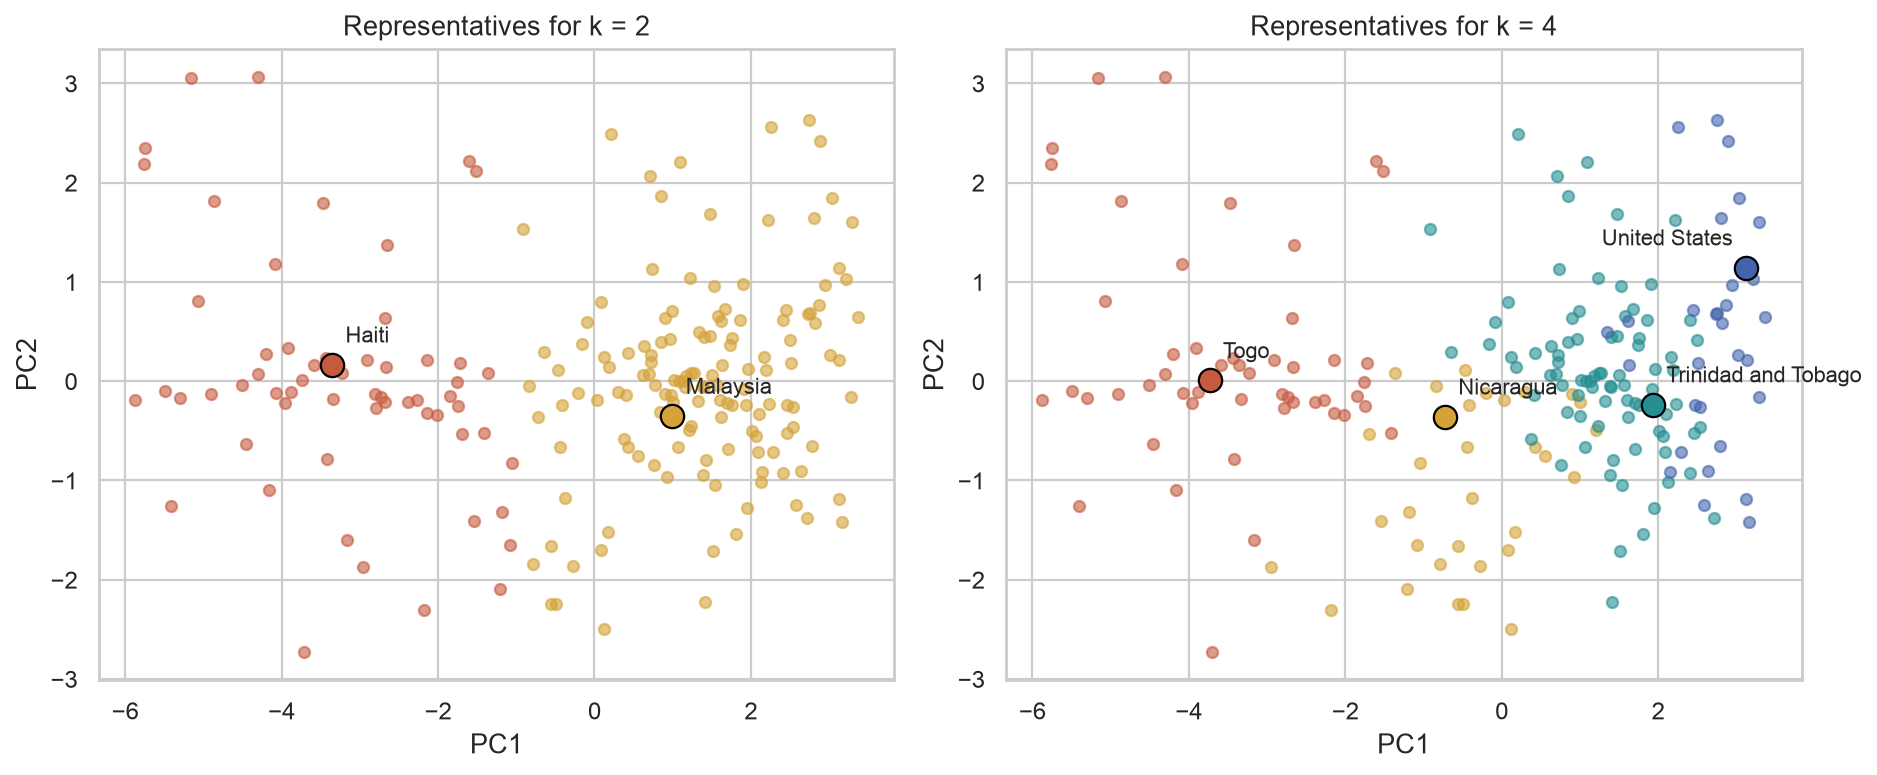

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, k, labels in zip(axes, [2, 4], [labels2, labels4]):
    for c in range(1, k+1):
        idx = labels == c
        ax.scatter(PC[idx, 0], PC[idx, 1], color=COLORS[c-1], alpha=.6, s=25)
        r = representatives[k][c]
        ax.scatter(PC[r, 0], PC[r, 1], color=COLORS[c-1], edgecolor='black', s=110)
        right_side = PC[r, 0] > 2
        ax.annotate(raw.loc[r, 'country'].replace('.', ' '), (PC[r, 0], PC[r, 1]), xytext=(-6 if right_side else 6, 10), textcoords='offset points', ha='right' if right_side else 'left', fontsize=10)
    ax.set(title=f'Representatives for k = {k}', xlabel='PC1', ylabel='PC2')
save_figure('07_representative_countries.png')

assignments = raw.copy()
assignments['imputed_indicators'] = imputed_count
assignments['cluster_k2'] = labels2
assignments['cluster_k4'] = labels4
assignments['silhouette_k2'] = silhouette_samples(PC, labels2)
assignments['silhouette_k4'] = silhouette_samples(PC, labels4)
for j in range(n90):
    assignments[f'PC{j+1}'] = PC[:, j]
assignments.to_csv(RESULTS / 'country_assignments.csv', index=False)
for k, labels in [(2, labels2), (4, labels4)]:
    print(f'\nk = {k}: members')
    for c in range(1, k+1):
        print(f'Group {c}: ' + ', '.join(raw.loc[labels == c, 'country']))

### Country interpretation

### Preferred model: two clusters

**Group 1: greater health and social disadvantage (60 countries/territories). Representative: Haiti.** Haiti has GDP per person of $386, female life expectancy of 56.0 years, and infant mortality of 82 per 1,000. These are close to the cluster medians of $381, 53.7 years and 86. Haiti's fertility of 4.6 is below the group median of 5.45, showing that a representative need not match every indicator. Its 57.8% female illiteracy is close to the group median of 58.2%. Many members are African countries, but Haiti, India and Pakistan also belong here. That geographic mixture shows why the model should not be interpreted as a continent label.

**Group 2: better average health and social outcomes, with varied incomes (138 countries/territories). Representative: Malaysia.** Malaysia has GDP per person of $4,313, female life expectancy of 74.3 years and infant mortality of 11, compared with medians of $3,248, 75.3 years and 17. Its fertility of 3.24 and female illiteracy of 21.9% exceed the cluster medians of 2.31 and 9.0%, so it is not typical on every dimension. Malaysia is the closest fully observed country to this centroid, yet the same cluster includes China, Brazil, Cuba, Japan and the United States. Calling all of these places uniformly “developed” would conceal substantial differences. In the historical file, China has GDP per person of $582 and Japan $41,718, despite sharing this broad group.

### More detailed comparison: four clusters

| Group | Size | Representative | Cluster GDP median (US$) | Female life expectancy median (years) | Infant mortality median (per 1,000) | Female economic activity median (%) |
|---|---:|---|---:|---:|---:|---:|
| 1 | 51 | Togo | 355 | 52.2 | 92 | 49.0 |
| 2 | 32 | Nicaragua | 1,655 | 70.3 | 39 | 26.1 |
| 3 | 84 | Trinidad and Tobago | 2,442 | 74.4 | 19 | 51.1 |
| 4 | 31 | United States | 23,530 | 80.2 | 6 | 51.5 |

**Group 1: lowest income and weakest health outcomes.** Togo's GDP per person of $322, female life expectancy of 51.5 years and infant mortality of 86 are close to the group medians. Its fertility of 6.08 and female illiteracy of 63% are also consistent with the group's high fertility and illiteracy. Haiti, Laos and Bangladesh appear alongside many African countries, so shared measured conditions cross geographic boundaries. Togo's economic activity is not especially low, which illustrates that participation alone is not a measure of prosperity.

**Group 2: intermediate health outcomes and lower female economic activity.** Nicaragua's female life expectancy of 70.6 years and infant mortality of 44 resemble the group medians of 70.3 and 39. Female economic activity is 33.4%, compared with the group's 26.1% and roughly 49–52% in the other groups. Its GDP per person of $464 is well below the group median, so it represents the combined profile better than the income level. Saudi Arabia is also in this group despite much higher GDP ($6,583): its low female economic activity (6.9%), high fertility (5.9), and high female illiteracy (49.8%) help explain the assignment. The data establish similarity on the indicators, not a common cause.

**Group 3: relatively good health and literacy with a broad income range.** Trinidad and Tobago has female life expectancy of 76.2 years, infant mortality of 14 and female illiteracy of 3%, compared with group medians of 74.4, 19 and 4.7%. Its GDP of $4,083 exceeds the group median of $2,442. China, Brazil and Cuba are also members. Cuba's female life expectancy of 78 years and infant mortality of 9 sit alongside GDP of $1,983, illustrating that health and GDP need not move in lockstep.

**Group 4: highest income and longest lives.** The United States has GDP per person of $26,037, female life expectancy of 80.1 years and infant mortality of 7, close to medians of $23,530, 80.2 and 6. Its female economic activity of 59.3% is above the group's 51.5%. Japan and many Western European countries join this cluster, but so do territories such as Puerto Rico and Réunion. Literacy is observed for only 11 of its 31 members: do not infer that this group is less literate than group 3 from the incomplete literacy medians.

All six representatives have observed values for all ten model inputs. They are selected by distance in the full five-component space, not by appearance on the two-dimensional plot. Cluster names describe this sample and are not official classifications or Gapminder income levels.

## 5. How sensitive is the result?

We check three reasonable alternatives, each refitting scaling and PCA: log GDP, complete cases, and only the four core variables used in the class clustering exercise (`lifeMale`, `lifeFemale`, `infantMortality`, `GDPperCapita`). We compare each alternative's assignments with the main model on the same rows using the **Adjusted Rand Index (ARI)**. One means identical partitions up to label names, while zero is agreement expected by chance.

Complete cases provide a useful check, but they are a smaller, selected sample. Changing the feature set also changes the research question. These comparisons do not select whichever preprocessing happens to produce a desired number of clusters.

In [12]:
checks = []
all_alternative_scores = []
core = ['lifeMale', 'lifeFemale', 'infantMortality', 'GDPperCapita']
for name in ['Log GDP', 'Complete cases', 'Class four indicators']:
    mask = imputed_count.eq(0) if name == 'Complete cases' else pd.Series(True, index=raw.index)
    selected = core if name == 'Class four indicators' else features
    alt = raw.loc[mask, selected].copy()
    alt = alt.fillna(alt.median())
    if name == 'Log GDP':
        alt['GDPperCapita'] = np.log1p(alt['GDPperCapita'])
    alt_pc = PCA(n_components=.90, svd_solver='full').fit_transform(StandardScaler().fit_transform(alt))
    fits = {k: KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(alt_pc) for k in range(2, 9)}
    sils = {k: silhouette_score(alt_pc, m.labels_) for k, m in fits.items()}
    for k, value in sils.items():
        all_alternative_scores.append({'alternative': name, 'k': k, 'silhouette': value, 'inertia': fits[k].inertia_})
    for k in [2, 4]:
        checks.append({'alternative': name, 'n': len(alt), 'PCs': alt_pc.shape[1], 'k': k,
                       'silhouette': sils[k], 'best_k_by_silhouette': max(sils, key=sils.get), 'best_silhouette': max(sils.values()),
                       'ARI_vs_main_same_k': adjusted_rand_score(models[k].labels_[mask.to_numpy()], fits[k].labels_)})
sensitivity = pd.DataFrame(checks)
display(sensitivity.round(3))
sensitivity.to_csv(RESULTS / 'sensitivity_checks.csv', index=False)
pd.DataFrame(all_alternative_scores).to_csv(RESULTS / 'sensitivity_all_k.csv', index=False)

,alternative,n,PCs,k,silhouette,best_k_by_silhouette,best_silhouette,ARI_vs_main_same_k
0,Log GDP,198,5,2,0.460,2,0.460,0.979
1,Log GDP,198,5,4,0.227,2,0.460,0.541
2,Complete cases,97,5,2,0.431,2,0.431,1.000
3,Complete cases,97,5,4,0.301,2,0.431,0.637
4,Class four indicators,198,2,2,0.603,3,0.610,0.879
5,Class four indicators,198,2,4,0.581,3,0.610,0.548


In [13]:
# Check whether different random initializations reach a similar partition.
stability = []
for k in [2, 4]:
    for seed in range(10):
        fit = KMeans(n_clusters=k, n_init=N_INIT, random_state=seed).fit(PC)
        stability.append({'k': k, 'seed': seed, 'inertia': fit.inertia_,
                          'ARI_vs_seed42': adjusted_rand_score(models[k].labels_, fit.labels_)})
stability = pd.DataFrame(stability)
display(stability.groupby('k').agg(min_ARI=('ARI_vs_seed42','min'), median_ARI=('ARI_vs_seed42','median'), min_inertia=('inertia','min'), max_inertia=('inertia','max')).round(3))
stability.to_csv(RESULTS / 'initialization_stability.csv', index=False)

,min_ARI,median_ARI,min_inertia,max_inertia
k,,,,
2,1.000,1.000,952.345,952.345
4,0.972,0.986,655.021,655.132


### What the sensitivity checks show

Log GDP still favors two clusters (silhouette 0.460), with ARI 0.979 against the main two-group partition. Among 97 complete cases, k=2 again has the best silhouette (0.431), and its assignments agree with the main model on those same rows (ARI 1.000). Four-group assignments change more: ARI 0.541 for log GDP and 0.637 for complete cases. These ARIs compare partitions, not accuracy against ground truth.

Using only the four class indicators favors three groups, showing that “how many worlds” depends on what we measure. Ten random seeds with 50 starts reproduce the two-group partition exactly; the four-group ARI ranges from about 0.972 to 1.000. Stable initializations do not establish real-world validity.

Median imputation can artificially pull observations toward the middle. The education exclusions narrow the meaning of development, although literacy remains included. Missingness is unlikely to be random, and complete cases are a selected sample. The source itself imputed some literacy observations. Correlated male/female health and literacy measures effectively give those themes repeated influence. GDP has a long upper tail. K-Means assumes Euclidean geometry and works best for roughly spherical groups. Historical country averages cannot establish causes, capture inequality within countries, or assign people to Gapminder income levels. Each country/territory counts once regardless of population.


## 6. Connection to Factfulness

*Factfulness* challenges the “gap instinct”: treating humanity as two homogeneous, opposing groups. Gapminder's [four income levels](https://www.gapminder.org/fw/income-levels/) describe people's living conditions along an income spectrum. They are **not** a claim that K-Means must discover four country clusters.

Our two-cluster model finds a useful broad contrast, but its better-outcome cluster includes countries with substantially different incomes and social conditions. Four clusters describe some of those differences, at the cost of weaker separation. The evidence supports being cautious about binary labels, **but it does not statistically establish four or more natural groups**.

Country GDP per person is not household income. These rows give equal weight to small territories and large countries, and country averages hide within-country inequality. We cannot identify Gapminder's household income levels from this dataset.

Other limits: the data are historical, missingness is substantial, several measures are correlated, and K-Means favors roughly spherical clusters under Euclidean distance. The selected number depends on the variables, transformations and analytical purpose. This is an exploratory description, not a causal analysis or an official classification.

In [14]:
# Save a compact machine-readable record and verify the central accounting.
assert len(assignments) + len(excluded) == len(df)
assert len(assignments) == profiles[2]['n'].sum() == profiles[4]['n'].sum()
assert cumulative[n90-1] >= .90 and cumulative[n90-2] < .90
assert np.all(np.diff(metrics['inertia']) < 0)
assert assignments['country'].is_unique
versions = {p: importlib.metadata.version(p) for p in ['numpy','pandas','scikit-learn','scipy','matplotlib','seaborn']}
summary = {'rows_original': len(df), 'rows_analyzed': len(raw), 'features': features,
           'imputed_cells': int(imputed_count.sum()), 'retained_components': n90,
           'retained_variance_pct': float(100*cumulative[n90-1]),
           'two_pc_variance_pct': float(100*cumulative[1]), 'best_k_by_silhouette': best_k,
           'source_url': URL, 'csv_sha256': hashlib.sha256(DATA.read_bytes()).hexdigest(),
           'versions': versions}
(RESULTS / 'summary.json').write_text(json.dumps(summary, indent=2))
print('Validation passed. Outputs saved in figures/ and results/.')
display(pd.Series(versions, name='Executed package version'))

Validation passed. Outputs saved in figures/ and results/.


numpy            2.3.5
pandas           2.2.3
scikit-learn     1.9.1
scipy           1.18.1
matplotlib      3.11.2
seaborn         0.13.2
Name: Executed package version, dtype: object

## Answers to the six research questions

### 1. Can the world be meaningfully divided into only two clusters?

**Yes as a coarse statistical summary, but not as two homogeneous categories called “developed” and “developing”.** The preferred two-group model separates 60 countries/territories with greater health and social disadvantage from 138 with better average outcomes. The second cluster remains very diverse: Malaysia, China, Cuba, Japan and the United States share it. Two clusters capture only 48.40% of dispersion in the retained PCA space, leaving substantial within-group differences.

### 2. How many clusters do the elbow and other metrics suggest?

**k=2 is the best-supported statistical choice for the main ten-indicator model.** The largest elbow bend is at two and its silhouette is 0.442, versus 0.283 for three and 0.284 for four. The inertia reduction is 48.40% from one to two, 18.88% from two to three, and 15.20% from three to four, followed by smaller gains. There is no strong second elbow establishing four. The PCA plots show overlapping groups rather than four isolated clouds.

We therefore retain k=2 as our preferred model and use k=4 as a richer descriptive comparison. Selection is sensitive to which variables define development: a separate model using only the four class indicators favors k=3 by silhouette. Log GDP and complete-case checks continue to favor k=2 for the ten-indicator approach.

### 3. How much structure do two clusters capture compared with the preferred number?

Our preferred number is two, so that literal comparison is identical. For a meaningful richer alternative, compare two with four:

| Measure | k=2, preferred | k=4, descriptive alternative |
|---|---:|---:|
| Within-cluster sum of squares in retained PCA space | 952.34 | 655.10 |
| PCA-space dispersion represented by cluster centers | 48.40% | 64.51% |
| Full ten-variable standardized dispersion represented | 45.15% | 60.56% |
| Mean silhouette | 0.442 | 0.284 |

Four clusters capture **16.10 percentage points** more PCA-space dispersion and reduce remaining within-cluster sum of squares by **31.21%** relative to two. This is a real gain in descriptive resolution, but adding clusters mechanically improves fit. The weaker silhouette indicates less distinct groups. These percentages are `1 − within-cluster SS / total SS`, not prediction accuracy, a fraction of countries correctly classified, or PCA explained variance.

### 4. Does this support Factfulness's argument for four or more groups?

**It supports the warning against simplistic binary labels, but it does not establish four or more natural clusters.** Four groups expose differences hidden in the broad two-group model, while separation metrics prefer two. Gapminder's four income levels describe people and households along an income spectrum. Our model groups equally weighted countries/territories using several indicators, including GDP per person. It cannot validate those household income bands or describe within-country inequality. This distinction follows [Gapminder's explanation of income levels](https://www.gapminder.org/fw/income-levels/).

### 5. What does PCA tell us about the variables that differentiate countries?

Five components retain **93.22%** of standardized variance. Two retain only **69.62%**, so clustering only the plotted two would discard too much information.

| Component | Variance explained | Cumulative |
|---|---:|---:|
| PC1 | 58.39% | 58.39% |
| PC2 | 11.23% | 69.62% |
| PC3 | 10.81% | 80.43% |
| PC4 | 7.83% | 88.26% |
| PC5 | 4.96% | 93.22% |

PC1 contrasts longer life expectancy and greater contraception use with high infant mortality, fertility and illiteracy. Its largest absolute coefficients are female life expectancy (+0.394), infant mortality (−0.389), male life expectancy (+0.381) and fertility (−0.372). Their squared contributions are about 15.5%, 15.1%, 14.5% and 13.8% of PC1, respectively.

PC2 is dominated by female economic activity (+0.845, about 71.4% of its squared coefficients), followed by male economic activity (+0.439). PC3 gives substantial weight to GDP (+0.512), male illiteracy (+0.433) and female illiteracy (+0.412), with economic activity also contributing. PCA therefore reveals several dimensions rather than a single income ranking. Signs can flip without changing the analysis. PCA usefully halves the number of dimensions, but it does not remove missingness bias or guarantee natural clusters.

### 6. How do representative countries explain the clusters?

See the detailed country interpretation in Part 4. Haiti and Malaysia represent the preferred two groups. Togo, Nicaragua, Trinidad and Tobago, and the United States represent the four-group comparison. Their observed values, similarities, differences and surprising neighbors are discussed there.

# Short group presentation

**Target: 2–3 minutes, about 320 spoken words.** Present directly from the notebook. Display cues are not spoken. Divide the sections among the group as convenient.

### 0:00–0:30 — Data and PCA

*Show the PCA variance plot.*

We asked whether the world really divides into developed and developing countries. We analyzed historical UN data covering 207 countries and territories. We removed education variables with too much missing data and nine poorly documented rows, filled remaining gaps with medians, and standardized ten indicators. Five principal components retained 93.2 percent of their variance. The biggest dimension combines life expectancy, infant mortality, fertility and literacy. Another captures economic participation.

### 0:30–1:10 — Cluster selection

*Show the elbow and silhouette plots, then the two-versus-four PCA plot.*

We tested two through eight clusters. Two had the strongest silhouette score, 0.442, and the clearest elbow. Four scored 0.284. So our preferred statistical model is two, even though the assignment asks us to consider a more complex world.

Two clusters explain 48.4 percent of dispersion in the retained PCA space. Four explain 64.5 percent, but more clusters automatically improve fit. Four give more detail with weaker separation.

### 1:10–2:05 — Countries make the distinction concrete

*Show the representative-country plot and the four-group profile table.*

Haiti represents the two-group model's more disadvantaged cluster. Malaysia represents the better-outcome group, which also contains China, Japan and the United States. That is a very broad category.

The four-group view separates Togo's low income and weak health profile, Nicaragua's intermediate health and lower female economic activity, Trinidad and Tobago's relatively good health and literacy, and the United States' high income and long life expectancy. These are the closest fully observed representatives in the five-component space.

Saudi Arabia shares Nicaragua's group despite higher income, showing that these clusters reflect more than wealth.

### 2:05–2:40 — Factfulness and conclusion

Our findings support Factfulness's warning against treating two labels as the whole story. But they do not prove that four natural groups exist. Gapminder describes household income levels, whereas we cluster country averages. The data are historical and incomplete. Our conclusion is that two clusters summarize the broad contrast, while four help describe diversity inside it. The appropriate detail depends on the question and the indicators.
